In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import os
# import re

In [2]:
os.getcwd()

'/Users/connor/Documents/github/sperm-data-analysis/notebooks'

In [3]:
none_barcode = "NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE"

fish_filter = ['fish1',    'fish10',    'fish12',    'fish13',    'fish14',    'fish15',
    'fish16',    'fish17',    'fish18',     'fish2',    'fish22',    'fish26',
    'fish35',    'fish37',    'fish38',     'fish4',    'fish40',    'fish42',
    'fish44',    'fish45',     'fish5',    'fish50',    'fish51',     'fish8']

sample_filter = 1

In [4]:
df = pd.read_csv(os.path.join('..', 'experiments', 'full_pipeline_keep_questionable', 'final_data.csv')) 

#3. APPLY SAMPLE FILTER
if sample_filter is not None:
    if isinstance(sample_filter, int):
        sample_filter = [sample_filter]
    df = df[df["sample"].isin(sample_filter)]

#4. APPLY FISH FILTER
if fish_filter is not None:
    if isinstance(fish_filter, str):
        fish_filter = [fish_filter]
    df = df[df["fish"].isin(fish_filter)]

#5. REMOVE "NONE" BARCODE AND FISHWATER SAMPLES
df = df[df["barcode"] != none_barcode]
df = df[~df["fish"].str.contains("fishwater", case=False)]

print("Samples included:", df["sample"].unique())
print("Fish included:", df["fish"].unique())

Samples included: [1]
Fish included: <StringArray>
[ 'fish1', 'fish10', 'fish13', 'fish14', 'fish15', 'fish17', 'fish18',
  'fish2', 'fish26', 'fish35', 'fish37', 'fish38', 'fish40', 'fish42',
 'fish45',  'fish5',  'fish8']
Length: 17, dtype: str


In [5]:
#6. COLLAPSE REPLICATES → per-fish barcode count table

# fish_barcode_counts is a DataFrame where each row is a fish, each column is a barcode,
# and the entry is the number of reads of that barcode
fish_barcode_counts = (
    df
    .groupby(["fish", "barcode"])["reads"]
    .sum()
    .unstack(fill_value=0)
)

# Reorder fish numerically
fish_barcode_counts = fish_barcode_counts.reindex(
    sorted(fish_barcode_counts.index, key=lambda x: int(x.replace("fish", "")))
)

fish_list = fish_barcode_counts.index.tolist()
n_fish = len(fish_list)

In [6]:
#6b. ORDER FISH NUMERICALLY
# def extract_fish_number(name):
#     match = re.search(r'(\d+)', name)
#     return int(match.group(1)) if match else float("inf")

# fish_all = list(fish_barcode_counts.index)

# fish_regular = sorted(
#     [f for f in fish_all if "fishctrl" not in f.lower()],
#     key=extract_fish_number
# )

# fish_ctrl = sorted(
#     [f for f in fish_all if "fishctrl" in f.lower()],
#     key=extract_fish_number
# )

# fish_order = fish_regular + fish_ctrl

# fish_barcode_counts = fish_barcode_counts.reindex(fish_order)

# fish_list = fish_barcode_counts.index.tolist()
# n_fish = len(fish_list)

In [7]:
#7. CALCULATE COSINE SIMILARITY
cos_sim_matrix = cosine_similarity(fish_barcode_counts)
cos_sim_df = pd.DataFrame(cos_sim_matrix, index=fish_list, columns=fish_list)

In [8]:
barcode_fish_appearances = (
    df.groupby("barcode")["fish"]
      .nunique()
      .rename("n_unique_fish")
)

def get_fish_barcodes(fish):
    """
    This function inputs a fish and returns a dataframe with the following columns:
    - barcode
    - reads
    - unique (boolean, True if the barcode does not appear in any other fish)
    """
    fish_barcodes = df[df['fish'] == fish].groupby('barcode', as_index = False).agg({'reads': 'sum'})
    fish_barcodes = fish_barcodes.join(
        barcode_fish_appearances.eq(1).rename("unique"),
        on="barcode"
    ).sort_values('reads', ascending = False)

    return fish_barcodes

In [9]:
#8. COMPUTE SHARED BARCODE COUNTS
shared_counts = np.dot(
    (fish_barcode_counts > 0).astype(int),
    (fish_barcode_counts > 0).astype(int).T
)
shared_df = pd.DataFrame(shared_counts, index=fish_list, columns=fish_list)

In [10]:
# custom_cmap = LinearSegmentedColormap.from_list(
#     "green_yellow_orange_shifted",
#     [
#         (0.00, "#4B9F97"),  
#         (0.25, "#CBEAAC"),
#         (1.00, "#A8A752")   
#     ],
#     N=256
# )

custom_cmap = LinearSegmentedColormap.from_list(
    "geyser",
    [
        (0.00, "#0B3A35"),
        (0.01, "#37736AFF"),
        (0.02, "#4B9B92FF"),
        (0.05, "#75A895FF"),
        (0.1, "#7BB594FF"),
        (0.25, "#A3D1A3FF"),
        (0.4, "#D6E29BFF"),
        (0.55, "#EAEA9DFF"),
        (0.7, "#E6DA75FF"),
        (0.85, "#ECC957FF"),
        (0.9, "#E8AB51FF"),
        (0.95, "#DE9C31FF"),
        (1.0, "#D77229FF")
    ],
    N=256
)

In [12]:
annot_font_size

7.15

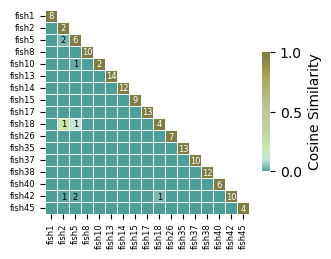

In [21]:
# 9. PLOT FISH-TO-FISH COSINE SIMILARITY
mask = np.triu(np.ones_like(cos_sim_df, dtype=bool), k=1)  # hide upper triangle

#Dynamically set figure size and font size
n_fish = len(fish_list)
fig_size = max(3.5, n_fish * 0.20)  # Slightly larger for more spacing
# annot_font_size = max(4, 8 - (n_fish * 0.05))  # Smaller annotations
# label_font_size = max(6, 11 - (n_fish * 0.08))
annot_font_size = 6
label_font_size = 6

plt.figure(figsize=(fig_size, fig_size))
ax = sns.heatmap(
    cos_sim_df,
    mask=mask,
    cmap=custom_cmap,
    fmt='d',
    annot_kws={"size": annot_font_size, "ha": "center", "va": "center"},
    cbar_kws={
        'label': 'Cosine Similarity',
        'shrink': 0.4,
        'aspect': 15
    },
    square=True,
    linewidths=0.5,
    xticklabels=True,  # Force all labels to show
    yticklabels=True   # Force all labels to show
)

# --- Annotate shared barcodes (only non-zero) ---
for i in range(len(shared_df)):
    for j in range(len(shared_df)):
        if mask[i, j]:   # skip masked upper triangle
            continue

        if i == j:
            fish_barcodes = get_fish_barcodes(shared_df.index[i])
            value = len(fish_barcodes[fish_barcodes['unique']])
        else:
            value = shared_df.iloc[i, j]
            
        if value != 0:
            ax.text(
                j + 0.5, i + 0.58,          # center of the square
                str(value),
                ha='center', va='center',
                fontsize=annot_font_size,
                color='white' if i == j else 'black',
            )

# Set font sizes for axis labels and ticks
ax.tick_params(axis='both', labelsize=label_font_size)
plt.setp(ax.get_xticklabels(), fontsize=label_font_size, rotation=0)
plt.setp(ax.get_yticklabels(), fontsize=label_font_size, rotation=0)

# Center tick marks in the middle of boxes
ax.set_xticks([i + 0.5 for i in range(len(fish_list))])
ax.set_yticks([i + 0.5 for i in range(len(fish_list))])
ax.set_xticklabels(fish_list, fontsize=label_font_size, rotation=90)
ax.set_yticklabels(fish_list, fontsize=label_font_size, rotation=0)

# Remove axis labels (but keep tick labels)
ax.set_xlabel('')
ax.set_ylabel('')

plt.tight_layout(pad=1.5)  # Add more padding to prevent label cutoff
#plt.savefig("Fig1_Cosine_v2.svg", bbox_inches='tight', transparent=True)
#plt.savefig("Fig1_Cosine_v2.png", dpi=600, bbox_inches='tight', transparent=True)

plt.savefig(os.path.join('images', 'cosine_fish.png'), dpi = 300)
plt.savefig(os.path.join('images', 'cosine_fish.svg'))

# Pie charts!

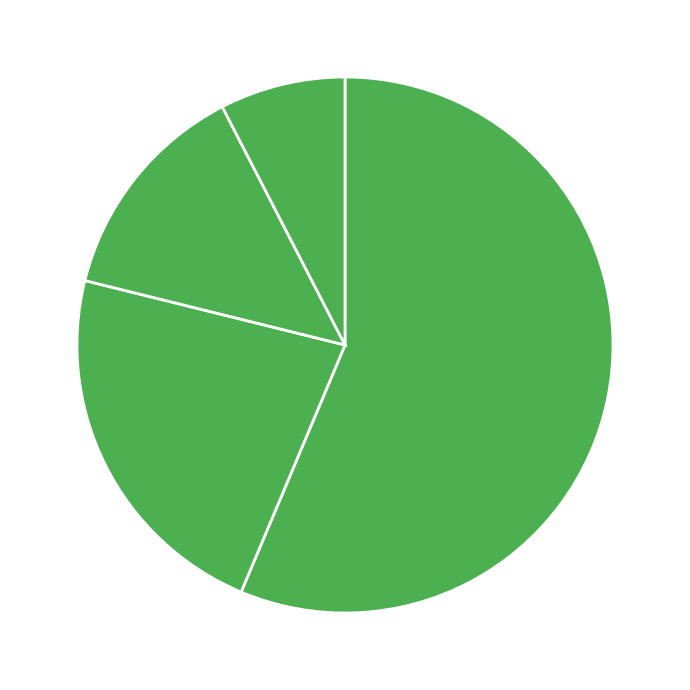

In [12]:
# Colors for unique vs shared
sizes = fish_barcodes["reads"]
colors = fish_barcodes["unique"].map({True: "#4CAF50", False: "#F44336"})

fig, ax = plt.subplots(figsize=(7, 7))

wedges, _ = ax.pie(
    sizes,
    labels=None,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops={"linewidth": 2, "edgecolor": "white"},
    radius=1.0
)

plt.tight_layout()
plt.show()

In [33]:
def plot_pie(ax, fish):
    fish_barcodes = get_fish_barcodes(fish)
    
    sizes = fish_barcodes["reads"]
    colors = fish_barcodes["unique"].map({True: "#36025c", False: "#D7C9F28C"})

    wedges, _ = ax.pie(
        sizes,
        labels=None,
        colors=colors,
        startangle=90,
        counterclock=False,
        wedgeprops={"linewidth": 0.5, "edgecolor": "white"},
        radius=1.0
    )

    fish_number = ''.join(filter(str.isdigit, fish_name))
    formatted_title = f"Fish {fish_number}"
    ax.set_title(formatted_title, fontsize=8.5, pad=3, fontweight='bold')

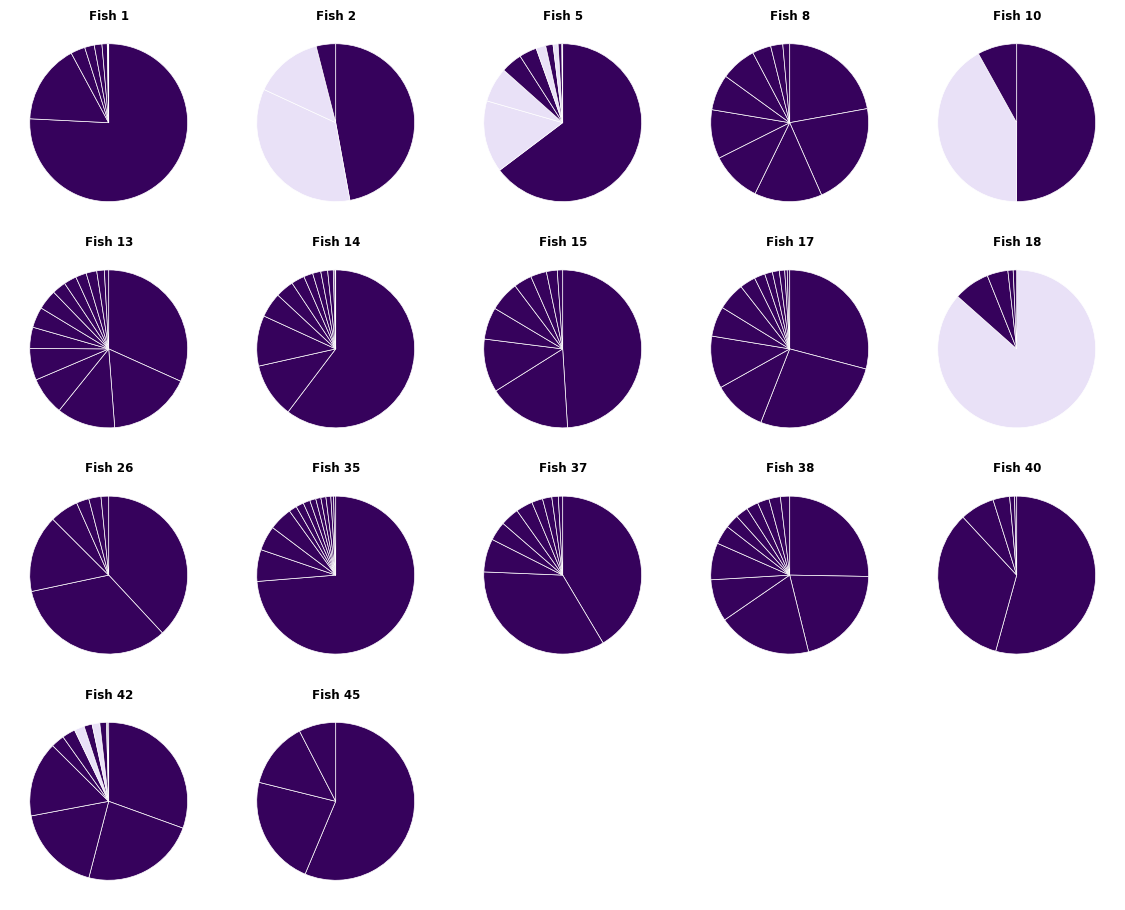

In [34]:
fishes = df['fish'].unique()
fishes = sorted(fishes, key=lambda x: int(x.replace("fish", "")))

n_rows = 4
n_cols = 5
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.3 * n_cols, 2.3 * n_rows))

ax = axes.ravel()
for i, fish_name in enumerate(fishes):
    plot_pie(ax[i], fish_name)
    
for i in range(17, 20):
    ax[i].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join('images', 'pie.png'), dpi = 300)
plt.savefig(os.path.join('images', 'pie.svg'))